## Cell 1 — Install & Import Libraries

In [1]:
# libs install

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping


## Cell 2 — Upload & Load the CSV

In [2]:
# Load eth_hourly.csv directly
filename = "eth_hourly.csv"
df = pd.read_csv(filename, parse_dates=['Date'])
df.sort_values('Date', inplace=True)
df.reset_index(drop=True, inplace=True)

# Rename columns to match expected format (lowercase to uppercase)
df.rename(columns={'close': 'Close', 'open': 'Open', 'high': 'High', 'low': 'Low', 'volume': 'Volume'}, inplace=True)

print(f"Loaded  : {filename}")
print(f"Shape   : {df.shape}  ({df['Date'].min().date()} → {df['Date'].max().date()})")
df.head()

Loaded  : eth_hourly.csv
Shape   : (3026, 6)  (2017-11-09 → 2026-02-20)


,Date,Close,High,Low,Open,Volume
0,2017-11-09,320.884003,329.451996,307.056000,308.644989,893249984
1,2017-11-10,299.252991,324.717987,294.541992,320.670990,885985984
2,2017-11-11,314.681000,319.453003,298.191986,298.585999,842300992
3,2017-11-12,307.907990,319.153015,298.513000,314.690002,1613479936
4,2017-11-13,316.716003,328.415009,307.024994,307.024994,1041889984


## Cell 3 — Explore & Visualise the Raw Data

    Basic Stats
          Open     High      Low    Close        Volume
count  3026.00  3026.00  3026.00  3026.00  3.026000e+03
mean   1700.94  1746.93  1650.47  1701.35  1.511417e+10
std    1293.42  1326.83  1256.54  1292.98  1.238208e+10
min      84.28    85.34    82.83    84.31  6.217330e+08
25%     360.11   371.50   351.37   360.05  6.346321e+09
50%    1661.01  1694.91  1629.50  1661.86  1.228010e+10
75%    2706.19  2794.14  2616.73  2705.51  2.019672e+10
max    4831.09  4953.73  4718.04  4831.35  9.773662e+10


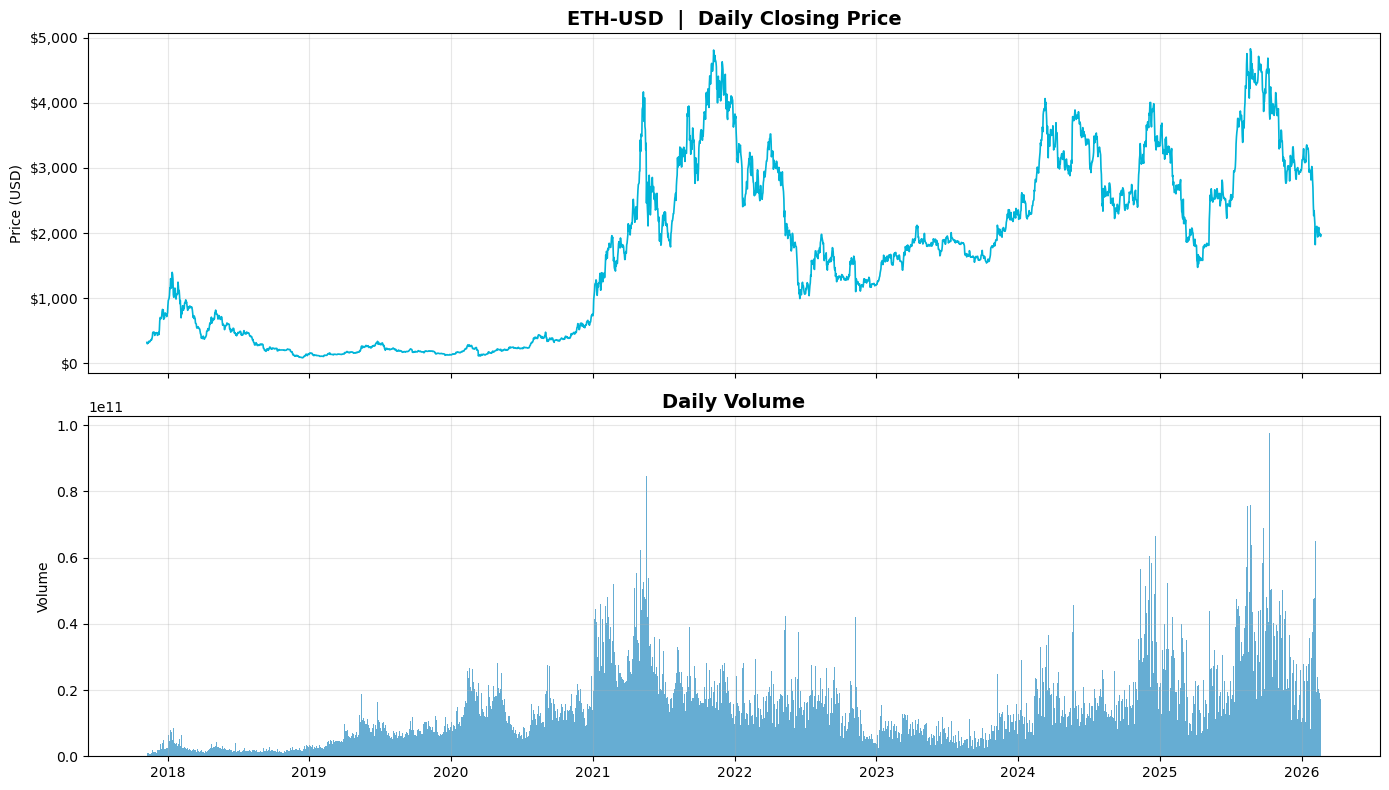

In [3]:
# Cell 3: Quick EDA
print("    Basic Stats")
print(df[['Open','High','Low','Close','Volume']].describe().round(2))

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Close price
axes[0].plot(df['Date'], df['Close'], color='#00B4D8', linewidth=1.2)
axes[0].set_title('ETH-USD  |  Daily Closing Price', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Price (USD)')
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x:,.0f}'))
axes[0].grid(alpha=0.3)

# Volume
axes[1].bar(df['Date'], df['Volume'], color='#0077B6', alpha=0.6, width=1)
axes[1].set_title('Daily Volume', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Volume')
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('eth_raw_data.png', dpi=150, bbox_inches='tight')
plt.show()

## Cell 4 — Preprocess: Scale + Build Sequences

In [4]:

WINDOW_SIZE = 60
TRAIN_RATIO = 0.80  # 80% train / 20% test split

# Scale to [0, 1]
scaler = MinMaxScaler(feature_range=(0, 1))
close_prices = df['Close'].values.reshape(-1, 1)
scaled = scaler.fit_transform(close_prices)

# Build (x, y) sliding-window sequences
def make_sequences(data, window):
    X, y = [], []
    for i in range(window, len(data)):
        X.append(data[i - window:i, 0])
        y.append(data[i, 0])
    return np.array(X), np.array(y)

X, y = make_sequences(scaled, WINDOW_SIZE)

# Train / test split
split = int(len(X) * TRAIN_RATIO)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# Reshape for samples, timesteps, and features
X_train = X_train.reshape(-1, WINDOW_SIZE, 1)
X_test  = X_test.reshape(-1, WINDOW_SIZE, 1)

print(f"Window size  : {WINDOW_SIZE} days")
print(f"Total seqs   : {len(X)}")
print(f"Train shape  : X={X_train.shape}  y={y_train.shape}")
print(f"Test  shape  : X={X_test.shape}   y={y_test.shape}")

Window size  : 60 days
Total seqs   : 2966
Train shape  : X=(2372, 60, 1)  y=(2372,)
Test  shape  : X=(594, 60, 1)   y=(594,)


## Cell 5 — Build the Plain RNN Model

In [5]:
# Plain RNN — two stacked SimpleRNN layers with Dropout 25% .

tf.random.set_seed(42)

model = Sequential([

    # Layer 1: RNN — returns full sequence so layer 2 can read it
    SimpleRNN(units=256,
              activation='tanh',
              return_sequences=True,
              input_shape=(WINDOW_SIZE, 1)),
    Dropout(0.25), # prevent overfitting

    # Layer 2: RNN — returns only the last hidden state
    SimpleRNN(units=128,
              activation='tanh',
              return_sequences=False),
    Dropout(0.25), # prevent overfitting

    # Output: single neuron to predicted (scaled) close price
    Dense(units=1)
])

model.compile(optimizer='adam', loss='mean_squared_error')
model.summary()

/opt/anaconda3/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 60, 256)        │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 128)            │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 115,457 (451.00 KB)

 Trainable params: 115,457 (451.00 KB)

 Non-trainable params: 0 (0.00 B)

## Cell 6 — Train the Model

In [6]:
# Cell 5: Training
# EarlyStopping halts training if val_loss stops improving, bascially saves time.

EPOCHS     = 100
BATCH_SIZE = 32

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=15,          # stop after 12 epochs without improvement
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.1,   # 10% of train used for validation
    callbacks=[early_stop],
    verbose=1
)

print(f"\nTraining stopped at epoch {len(history.history['loss'])}")
print(f"Best val_loss : {min(history.history['val_loss']):.6f}")


Epoch 1/100
67/67 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - loss: 0.0816 - val_loss: 0.0026
Epoch 2/100
67/67 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 0.0122 - val_loss: 0.0010
Epoch 3/100
67/67 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 0.0079 - val_loss: 0.0065
Epoch 4/100
67/67 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 0.0049 - val_loss: 0.0015
Epoch 5/100
67/67 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 0.0046 - val_loss: 0.0012
Epoch 6/100
67/67 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 0.0030 - val_loss: 5.7057e-04
Epoch 7/100
67/67 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 0.0026 - val_loss: 6.7931e-04
Epoch 8/100
67/67 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 0.0027 - val_loss: 7.0232e-04
Epoch 9/100
67/67 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 0.0024 - val_loss: 5.5272e-04
Epoch 10/100
67/67 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 0.0022 - val_loss: 5.6818e-04
Epoch 11/100
67/67 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - loss: 0.0022 - val_loss: 4.5494e-04
Epoch 12/100
67/67 ━━━━━━━━━

## Cell 6 — Plot Training Loss

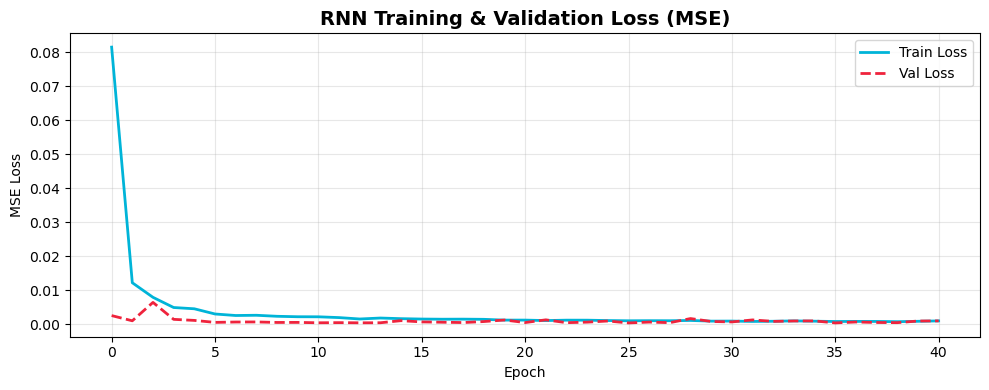

In [7]:
# Cell 6: Loss Curves
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(history.history['loss'],     label='Train Loss', color='#00B4D8', linewidth=2)
ax.plot(history.history['val_loss'], label='Val Loss',   color='#EF233C', linewidth=2, linestyle='--')
ax.set_title('RNN Training & Validation Loss (MSE)', fontsize=14, fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('MSE Loss')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('rnn_loss_curve.png', dpi=150, bbox_inches='tight')
plt.show()

## Cell 7 — Predictions & Inverse Scale

In [8]:
# Cell 7: Generate Predictions

# Predict on both sets
pred_train_scaled = model.predict(X_train)
pred_test_scaled  = model.predict(X_test)

# Inverse transform back to real USD values
pred_train = scaler.inverse_transform(pred_train_scaled)
pred_test  = scaler.inverse_transform(pred_test_scaled)
actual_train = scaler.inverse_transform(y_train.reshape(-1, 1))
actual_test  = scaler.inverse_transform(y_test.reshape(-1, 1))

# Align dates (offset by WINDOW_SIZE since we need a look-back window)
dates_all   = df['Date'].values[WINDOW_SIZE:]
dates_train = dates_all[:split]
dates_test  = dates_all[split:]

print(f"Train predictions : {len(pred_train)} points")
print(f"Test  predictions : {len(pred_test)} points")
print("Predictions ready.")

75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
Train predictions : 2372 points
Test  predictions : 594 points
Predictions ready.


## Cell 8 — Prediction vs Actual Chart (Presentation Ready)

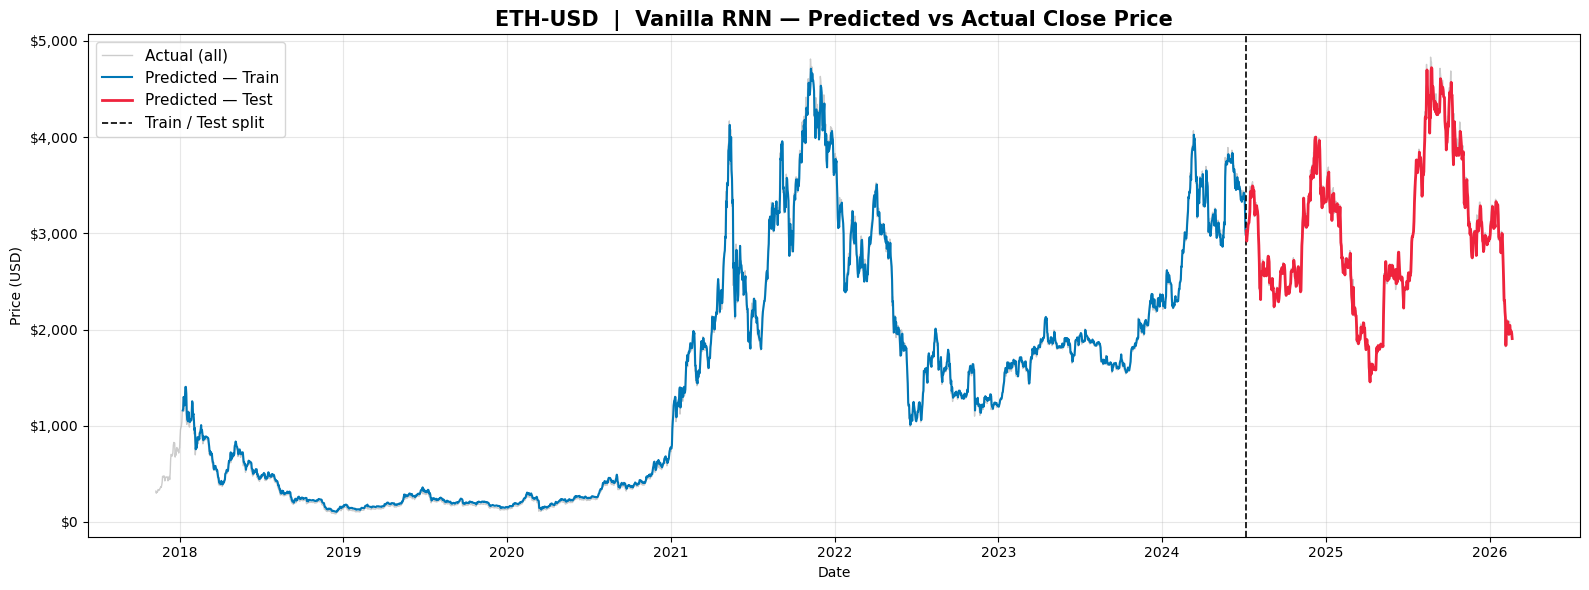

In [9]:
# Cell 8: Prediction vs Actual Chart

fig, ax = plt.subplots(figsize=(16, 6))

# Full actual price (background reference)
ax.plot(df['Date'], df['Close'], color='#CCCCCC', linewidth=1, label='Actual (all)', zorder=1)

# Train fit
ax.plot(dates_train, pred_train, color='#0077B6', linewidth=1.5,
        label='Predicted — Train', zorder=2)

# Test prediction
ax.plot(dates_test, pred_test, color='#EF233C', linewidth=2,
        label='Predicted — Test', zorder=3)

# Vertical split line
ax.axvline(x=dates_test[0], color='black', linestyle='--', linewidth=1.2,
           label='Train / Test split')

ax.set_title('ETH-USD  |  Vanilla RNN — Predicted vs Actual Close Price',
             fontsize=15, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Price (USD)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.legend(fontsize=11)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('rnn_prediction_chart.png', dpi=150, bbox_inches='tight')
plt.show()

## Cell 9 — Evaluation Metrics

In [10]:
# Cell 9: Metrics
# Use these stats directly on presentation slides.

def evaluate(actual, predicted, label):
    mae  = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2   = r2_score(actual, predicted)
    mape = np.mean(np.abs((actual - predicted) / actual)) * 100
    print(f"{'─'*40}")
    print(f" {label}")
    print(f"{'─'*40}")
    print(f"  MAE   : ${mae:>10,.2f}")
    print(f"  RMSE  : ${rmse:>10,.2f}")
    print(f"  MAPE  : {mape:>9.2f}%")
    print(f"  R²    : {r2:>11.4f}")
    return {'MAE': mae, 'RMSE': rmse, 'MAPE': mape, 'R2': r2}

train_metrics = evaluate(actual_train, pred_train, 'TRAIN SET')
test_metrics  = evaluate(actual_test,  pred_test,  'TEST SET')


────────────────────────────────────────
 TRAIN SET
────────────────────────────────────────
  MAE   : $     48.80
  RMSE  : $     79.19
  MAPE  :      6.31%
  R²    :      0.9957
────────────────────────────────────────
 TEST SET
────────────────────────────────────────
  MAE   : $     84.03
  RMSE  : $    117.27
  MAPE  :      2.82%
  R²    :      0.9759


## Cell 10 — Zoom: Last 180 Days Test Period

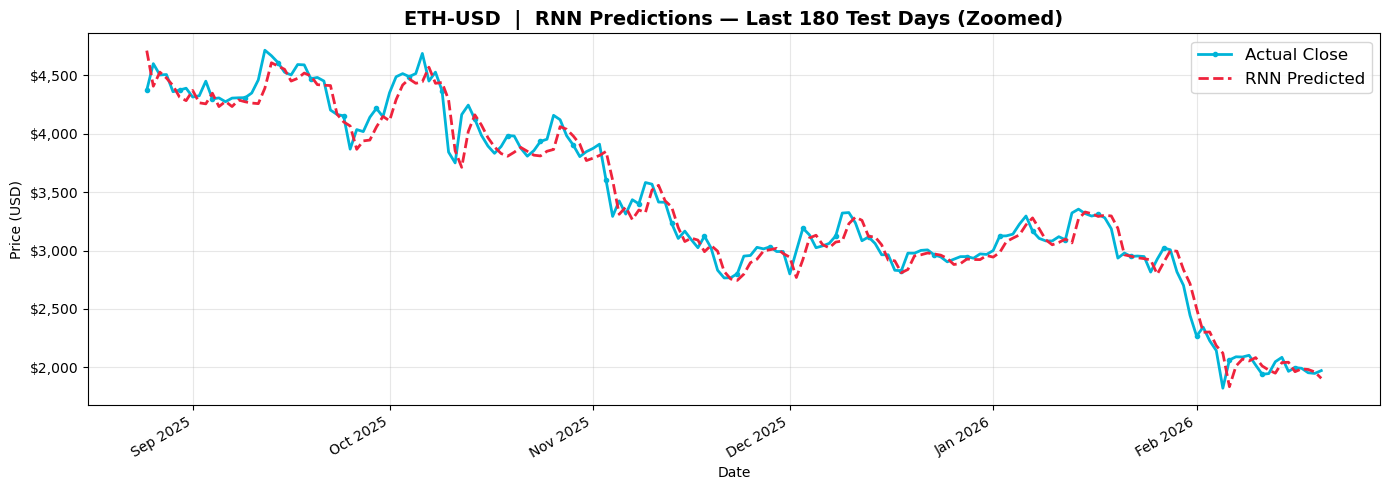

In [11]:
# Cell 10: Zoomed Test Window
# Great for a close-up slide showing how the model tracks price movement.

ZOOM_DAYS = 180

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(dates_test[-ZOOM_DAYS:], actual_test[-ZOOM_DAYS:],
        color='#00B4D8', linewidth=2, label='Actual Close', marker='o',
        markersize=3, markevery=5)
ax.plot(dates_test[-ZOOM_DAYS:], pred_test[-ZOOM_DAYS:],
        color='#EF233C', linewidth=2, label='RNN Predicted', linestyle='--')

ax.set_title(f'ETH-USD  |  RNN Predictions — Last {ZOOM_DAYS} Test Days (Zoomed)',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Price (USD)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
plt.xticks(rotation=30, ha='right')
ax.legend(fontsize=12)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('rnn_zoom_test.png', dpi=150, bbox_inches='tight')
plt.show()